Acceder a los datos es bd y generar dos datasets hora y dia

In [1]:
from datetime import datetime
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import seaborn as sns

In [2]:
try:
    connection = sqlite3.connect("estacion_contaminantes_unam_mes060708.db")
except Exception as e:
    print('Error al conectar a db' + str(e))
try:
    df = pd.read_sql_query("SELECT fecha, pm2_5 FROM pms7003 where fecha between '2026-06-09 12:25' and '2026-08-11 12:01'", connection)
except Exception as e:
    print('Error al ejecutar query \t'+str(e))

In [3]:
datos_estacion_unam = df
datos_estacion_unam.head()

,fecha,pm2_5
0,2026-06-09 12:25,28.555556
1,2026-06-09 12:30,27.500000
2,2026-06-09 12:35,27.200000
3,2026-06-09 12:40,27.400000
4,2026-06-09 12:45,28.000000


asegura que fecha es datetime y elimina datos en 0 

In [4]:
if 'fecha' in datos_estacion_unam.columns:
    datos_estacion_unam['fecha'] = pd.to_datetime(datos_estacion_unam['fecha'], errors='coerce')
    datos_estacion_unam= datos_estacion_unam.set_index('fecha')
datos_estacion_unam.drop(datos_estacion_unam[datos_estacion_unam['pm2_5'] == 0].index, inplace=True)

resample por hora y relleno de datos faltantes si es solo uno

In [5]:
datos_hora = datos_estacion_unam.resample('h').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['pm2_5'] == 0) | (datos_copy['pm2_5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['pm2_5']
            val_posterior = datos_copy.iloc[i+1]['pm2_5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'pm2_5'] = valor_interpolado
    
datos_hora_interpolados = datos_copy
datos_hora_interpolados.head()

,fecha,pm2_5
0,2026-06-09 12:00:00,27.736508
1,2026-06-09 13:00:00,25.633333
2,2026-06-09 14:00:00,24.633333
3,2026-06-09 15:00:00,25.258333
4,2026-06-09 16:00:00,30.666667


dibuja grafica temporal de los datos 

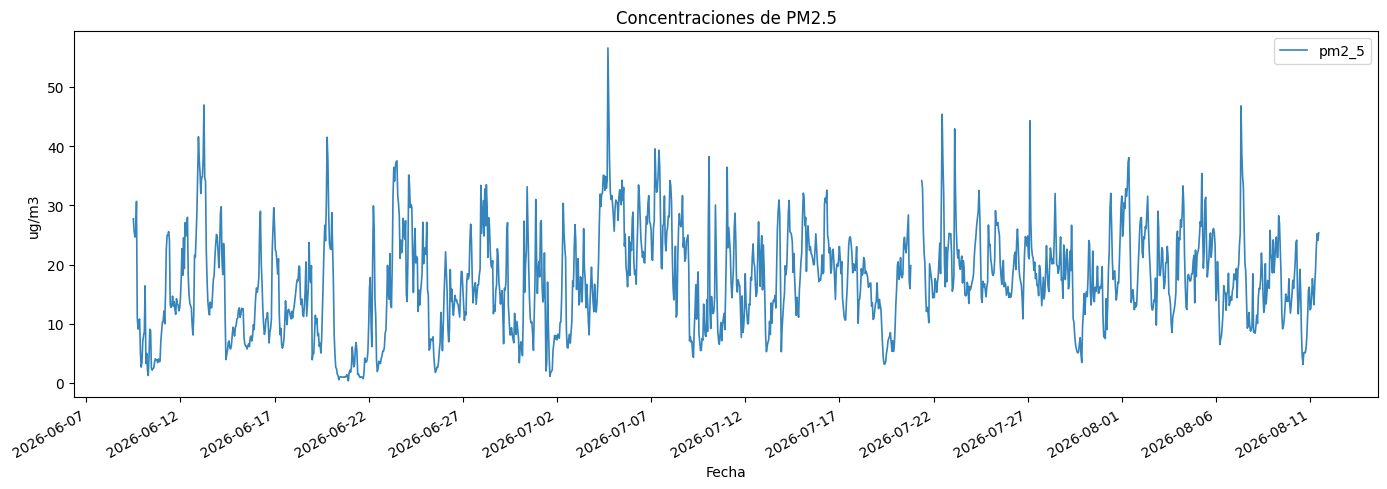

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_hora_interpolados['fecha'], datos_hora_interpolados["pm2_5"], label="pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

carga los datos de la estacion roua desde csv

In [7]:
def load_df_from_file(name):
    try:
        df = pd.read_csv(name)
        print("file loaded with columns : ")
        print(df.columns)
        return df
    except FileNotFoundError:
        print("File not found. Please ensure '"+name+"' is in the current directory.")
        return None

name = 'datos ruoa 06,07,08\\completo.csv'
datos_ruoa = load_df_from_file(name) 
datos_ruoa.head()

file loaded with columns : 
Index(['Time', 'O3', 'O3_flag', 'SO2', 'SO2_flag', 'NO2', 'NO2_flag', 'NO',
       'NO_flag', 'CO', 'CO_flag', 'PM10', 'PM10_flag', 'PM2.5', 'PM2.5_flag'],
      dtype='str')


,Time,O3,O3_flag,SO2,SO2_flag,NO2,NO2_flag,NO,NO_flag,CO,CO_flag,PM10,PM10_flag,PM2.5,PM2.5_flag
0,2026-06-01 00:00:00,39.72,OK,1.64,OK,0.61,OK,-0.23,BDL,0.20,OK,NaN,OS,17.55,OK
1,2026-06-01 01:00:00,36.77,OK,1.19,OK,0.75,OK,-0.23,BDL,0.20,OK,NaN,OS,8.99,OK
2,2026-06-01 02:00:00,29.57,OK,1.30,OK,1.02,OK,-0.24,BDL,0.21,OK,NaN,OS,12.45,OK
3,2026-06-01 03:00:00,22.86,OK,1.06,OK,1.40,OK,-0.23,BDL,0.22,OK,NaN,OS,11.49,OK
4,2026-06-01 04:00:00,22.22,OK,1.58,OK,1.85,OK,-0.21,BDL,0.20,OK,NaN,OS,12.99,OK


In [8]:
datos_ruoa_pm25 = datos_ruoa[['Time', 'PM2.5', 'PM2.5_flag']]
datos_ruoa_pm25.size

5058

filtro de acuerdo a la bandera

In [9]:
datos_ruoa_pm25 = datos_ruoa_pm25[datos_ruoa_pm25['PM2.5_flag'] == 'OK']
datos_ruoa_pm25 = datos_ruoa_pm25[(datos_ruoa_pm25['Time'] >= '2026-06-09 12:00') & (datos_ruoa_pm25['Time'] <= '2026-08-11 11:05')]
datos_ruoa_pm25.head()

,Time,PM2.5,PM2.5_flag
204,2026-06-09 12:00:00,14.97,OK
205,2026-06-09 13:00:00,17.18,OK
206,2026-06-09 14:00:00,25.75,OK
207,2026-06-09 15:00:00,11.07,OK
208,2026-06-09 16:00:00,26.50,OK


resampleado por hora y dia

In [10]:
datos_ruoa_pm25 = datos_ruoa_pm25[['Time', 'PM2.5']]
if 'Time' in datos_ruoa_pm25.columns:
    datos_ruoa_pm25['Time'] = pd.to_datetime(datos_ruoa_pm25['Time'], errors='coerce')
    datos_ruoa_pm25= datos_ruoa_pm25.set_index('Time')
datos_ruoa_pm25.drop(datos_ruoa_pm25[datos_ruoa_pm25['PM2.5'] == 0].index, inplace=True)

datos_hora = datos_ruoa_pm25.resample('h').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['PM2.5'] == 0) | (datos_copy['PM2.5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['PM2.5']
            val_posterior = datos_copy.iloc[i+1]['PM2.5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'PM2.5'] = valor_interpolado
    
datos_ruoa_interpolados = datos_copy
datos_ruoa_interpolados.head()

,Time,PM2.5
0,2026-06-09 12:00:00,14.97
1,2026-06-09 13:00:00,17.18
2,2026-06-09 14:00:00,25.75
3,2026-06-09 15:00:00,11.07
4,2026-06-09 16:00:00,26.50


dibuja grafica 

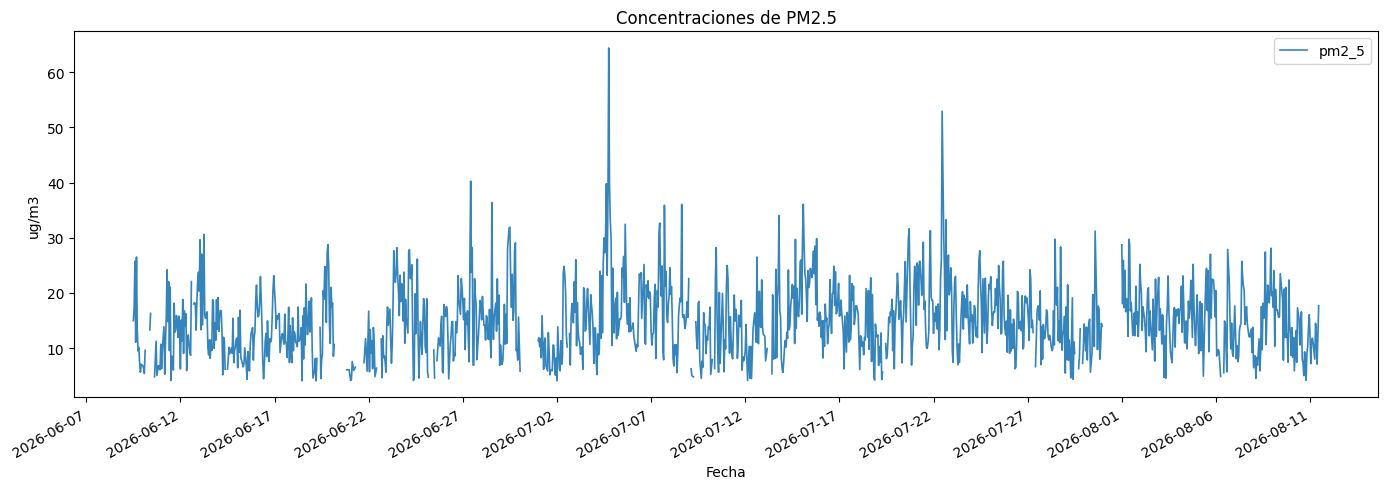

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_ruoa_interpolados['Time'], datos_ruoa_interpolados["PM2.5"], label="pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

dubuja grafica con las dos estaciones

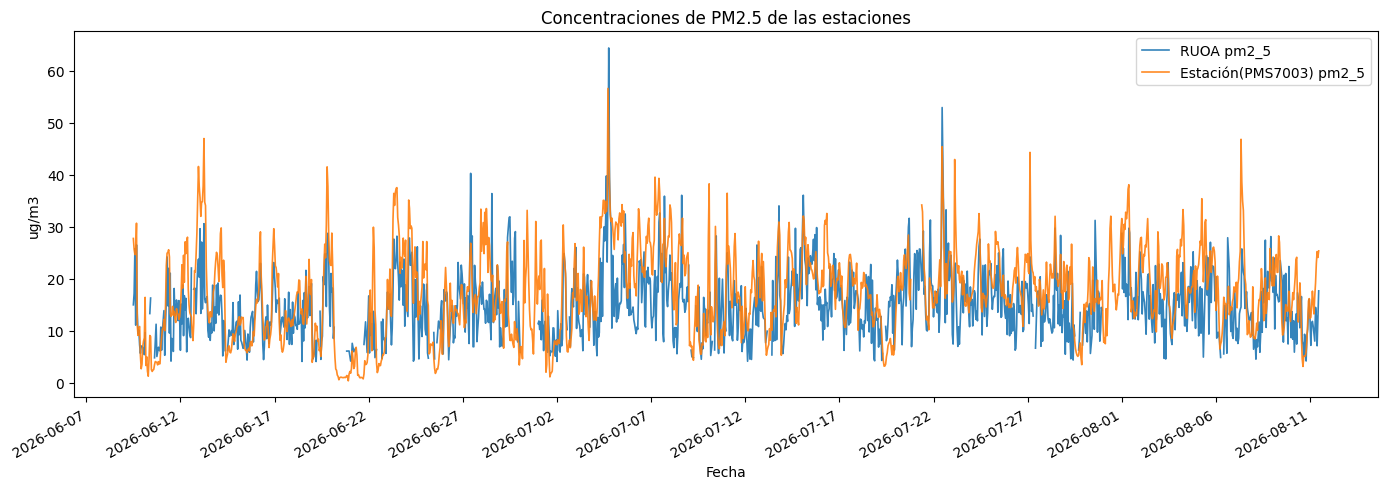

In [12]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_ruoa_interpolados['Time'], datos_ruoa_interpolados["PM2.5"], label="RUOA pm2_5", linewidth=1.2, alpha=0.9)
ax.plot(datos_hora_interpolados['fecha'], datos_hora_interpolados["pm2_5"], label="Estación(PMS7003) pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5 de las estaciones")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

unir ambos dataframes y generar grafico de dispersion con R2

In [13]:
datos_ruoa_interpolados.rename(columns={'Time': 'fecha', 'PM2.5': 'pm2_5'}, inplace=True)
datos_unidos_n = datos_hora_interpolados.merge(datos_ruoa_interpolados, how = 'inner', on ="fecha", suffixes=('_pms7003', '_ruoa'))
datos_unidos = datos_unidos_n[datos_unidos_n['pm2_5_ruoa'].notna() & datos_unidos_n['pm2_5_pms7003'].notna()]
datos_unidos.head()

,fecha,pm2_5_pms7003,pm2_5_ruoa
0,2026-06-09 12:00:00,27.736508,14.97
1,2026-06-09 13:00:00,25.633333,17.18
2,2026-06-09 14:00:00,24.633333,25.75
3,2026-06-09 15:00:00,25.258333,11.07
4,2026-06-09 16:00:00,30.666667,26.50


grafico de dispersion

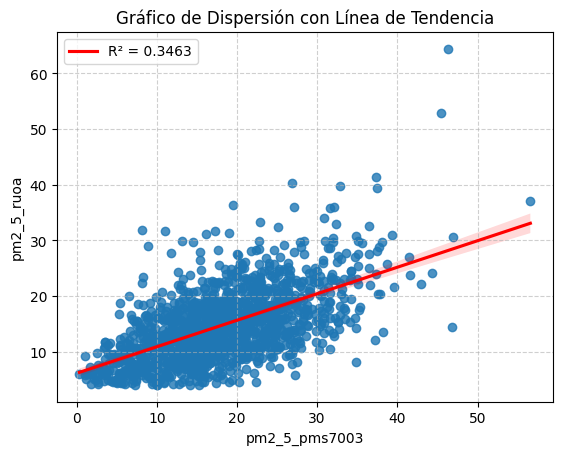

El coeficiente de determinación (R²) es: 0.3463


In [14]:

slope, intercept, r_value, p_value, std_err = stats.linregress(datos_unidos['pm2_5_pms7003'], datos_unidos['pm2_5_ruoa'])

r_cuadrado = r_value ** 2

# 3. Crear el gráfico de dispersión con la línea de ajuste
# Se añade el valor de R² en la leyenda de la línea
sns.regplot(
    data=datos_unidos, 
    x='pm2_5_pms7003', 
    y='pm2_5_ruoa', 
    line_kws={'label': f'R² = {r_cuadrado:.4f}', 'color': 'red'}
)

# Configuraciones adicionales del gráfico
plt.title('Gráfico de Dispersión con Línea de Tendencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar el gráfico
plt.show()

# 4. Imprimir el resultado en consola
print(f"El coeficiente de determinación (R²) es: {r_cuadrado:.4f}")

mediciones estadisticas

In [15]:

mae = mean_absolute_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_pms7003'])
mse =  mean_squared_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_pms7003'])
rmse = np.sqrt(mean_squared_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_pms7003']))
mape = mean_absolute_percentage_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_pms7003'])
r2 = r2_score(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_pms7003'])

print("\t MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):")
print(f"MAE  (Error absoluto medio): {mae:.4f}")
print(f"MSE (Error cuadratico medio): {mse:.4f}")
print(f"MAPE : {mape:.1f}%")
print(f"RMSE (Raíz error cuadrático medio): {rmse:.4f}")
print(f"R²   (Coeficiente de determinación): {r2:.4f}")

	 MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):
MAE  (Error absoluto medio): 5.8504
MSE (Error cuadratico medio): 55.9761
MAPE : 0.5%
RMSE (Raíz error cuadrático medio): 7.4817
R²   (Coeficiente de determinación): -0.3320


promedios por dia

In [16]:
datos_dia = datos_estacion_unam.resample('D').mean().fillna(np.nan).reset_index()
datos_copy = datos_dia.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['pm2_5'] == 0) | (datos_copy['pm2_5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['pm2_5']
            val_posterior = datos_copy.iloc[i+1]['pm2_5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'pm2_5'] = valor_interpolado
    
datos_dia_interpolados = datos_copy
datos_dia_interpolados.head()

,fecha,pm2_5
0,2026-06-09,15.127018
1,2026-06-10,5.036806
2,2026-06-11,14.942361
3,2026-06-12,20.738194
4,2026-06-13,24.573264


In [17]:
if 'Time' in datos_ruoa_pm25.columns:
    datos_ruoa_pm25['Time'] = pd.to_datetime(datos_ruoa_pm25['Time'], errors='coerce')
    datos_ruoa_pm25= datos_ruoa_pm25.set_index('Time')
datos_ruoa_pm25.drop(datos_ruoa_pm25[datos_ruoa_pm25['PM2.5'] == 0].index, inplace=True)

datos_hora = datos_ruoa_pm25.resample('D').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['PM2.5'] == 0) | (datos_copy['PM2.5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['PM2.5']
            val_posterior = datos_copy.iloc[i+1]['PM2.5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'PM2.5'] = valor_interpolado
    
datos_ruoa_dia = datos_copy
datos_ruoa_dia.head()

,Time,PM2.5
0,2026-06-09,13.473636
1,2026-06-10,8.356923
2,2026-06-11,12.829130
3,2026-06-12,14.495000
4,2026-06-13,16.010417


grafico temporal

In [18]:

datos_ruoa_dia.rename(columns={'Time': 'fecha', 'PM2.5': 'pm2_5'}, inplace=True)
datos_unidos_n = datos_dia_interpolados.merge(datos_ruoa_dia, how = 'inner', on ="fecha", suffixes=('_pms7003', '_ruoa'))
datos_unidos_dia = datos_unidos_n[datos_unidos_n['pm2_5_ruoa'].notna() & datos_unidos_n['pm2_5_pms7003'].notna()]
datos_unidos_dia.head()

,fecha,pm2_5_pms7003,pm2_5_ruoa
0,2026-06-09,15.127018,13.473636
1,2026-06-10,5.036806,8.356923
2,2026-06-11,14.942361,12.829130
3,2026-06-12,20.738194,14.495000
4,2026-06-13,24.573264,16.010417


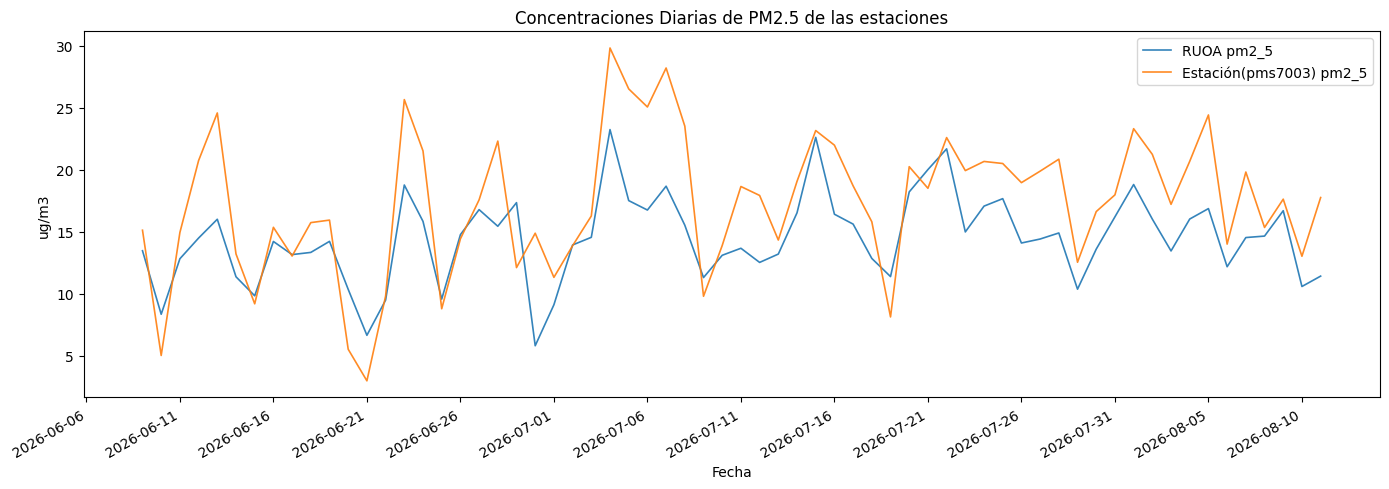

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_unidos_dia['fecha'], datos_unidos_dia["pm2_5_ruoa"], label="RUOA pm2_5", linewidth=1.2, alpha=0.9)
ax.plot(datos_unidos_dia['fecha'], datos_unidos_dia["pm2_5_pms7003"], label="Estación(pms7003) pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones Diarias de PM2.5 de las estaciones")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

grafico de dispersion

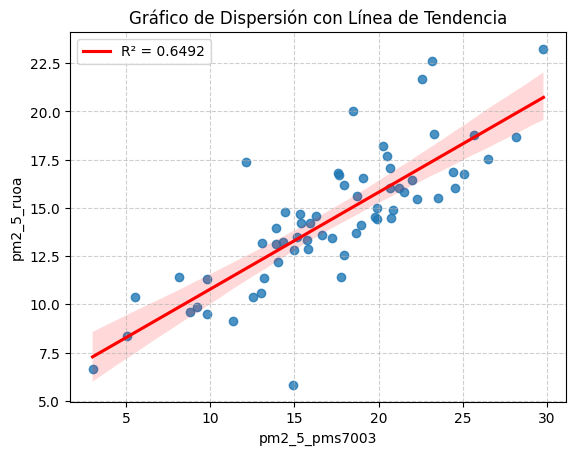

El coeficiente de determinación (R²) es: 0.6492


In [20]:
slope, intercept, r_value, p_value, std_err = stats.linregress(datos_unidos_dia['pm2_5_pms7003'], datos_unidos_dia['pm2_5_ruoa'])

r_cuadrado = r_value ** 2

# 3. Crear el gráfico de dispersión con la línea de ajuste
# Se añade el valor de R² en la leyenda de la línea
sns.regplot(
    data=datos_unidos_dia, 
    x='pm2_5_pms7003', 
    y='pm2_5_ruoa', 
    line_kws={'label': f'R² = {r_cuadrado:.4f}', 'color': 'red'}
)

# Configuraciones adicionales del gráfico
plt.title('Gráfico de Dispersión con Línea de Tendencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar el gráfico
plt.show()

# 4. Imprimir el resultado en consola
print(f"El coeficiente de determinación (R²) es: {r_cuadrado:.4f}")

In [21]:

mae = mean_absolute_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_pms7003'])
mse =  mean_squared_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_pms7003'])
rmse = np.sqrt(mean_squared_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_pms7003']))
mape = mean_absolute_percentage_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_pms7003'])
r2 = r2_score(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_pms7003'])

print("\t MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):")
print(f"MAE  (Error absoluto medio): {mae:.4f}")
print(f"MSE (Error cuadratico medio): {mse:.4f}")
print(f"MAPE : {mape:.1f}%")
print(f"RMSE (Raíz error cuadrático medio): {rmse:.4f}")
print(f"R²   (Coeficiente de determinación): {r2:.4f}")

	 MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):
MAE  (Error absoluto medio): 3.6483
MSE (Error cuadratico medio): 19.9307
MAPE : 0.3%
RMSE (Raíz error cuadrático medio): 4.4644
R²   (Coeficiente de determinación): -0.6828
